# Statistical Analysis and Feature Engineering

Statistical analysis and Feature Engineering with interim database processed in `01_eda.ipynb`,

### Libraries

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from online_retail.analysis.plots import (
    plot_country_transactions,
    plot_monthly_seasonality,
    plot_sales_over_time,
    sales_over_time,
    transactions_by_country,
)


In [3]:
# Works when Jupyter starts from either the repository root or notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent


### Analysis

In [4]:
df = pd.read_parquet(ROOT / "data/interim/purchases.parquet")


In [4]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom
...,...,...,...,...,...,...,...,...
768992,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
768993,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
768994,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
768995,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


In [ ]:
df['Customer ID'].nunique() # this is the customer base

5878

## Sales and customer activity over time

Revenue below is positive-price purchase value, **not net revenue after returns**.
Transactions count distinct invoices, not product lines. Customers are unique within each period;
monthly customer counts cannot be summed to obtain the total customer base.
All charts describe identified customers retained by cleansing, not the entire original retailer.


In [15]:
monthly = sales_over_time(df, "MS")
weekly = sales_over_time(df, "W-MON")
monthly

,revenue,quantity,transactions,customers
InvoiceDate,,,,
2009-12-01,686525.660,400126,1506,954
2010-01-01,557229.062,370901,1007,719
2010-02-01,506356.066,372760,1103,772
2010-03-01,699608.991,503466,1524,1057
2010-04-01,594541.692,352017,1325,940
2010-05-01,599955.790,386295,1375,966
2010-06-01,638305.530,391669,1492,1040
2010-07-01,591576.740,325651,1377,927
2010-08-01,604212.650,453579,1291,911


The first and last calendar months may have incomplete coverage. Keep them visible
in the chronological charts, but exclude both conservatively from calendar-month comparisons.
Zero-filled periods assume continuous data coverage; a zero can also indicate missing source data.


Observed transactions: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


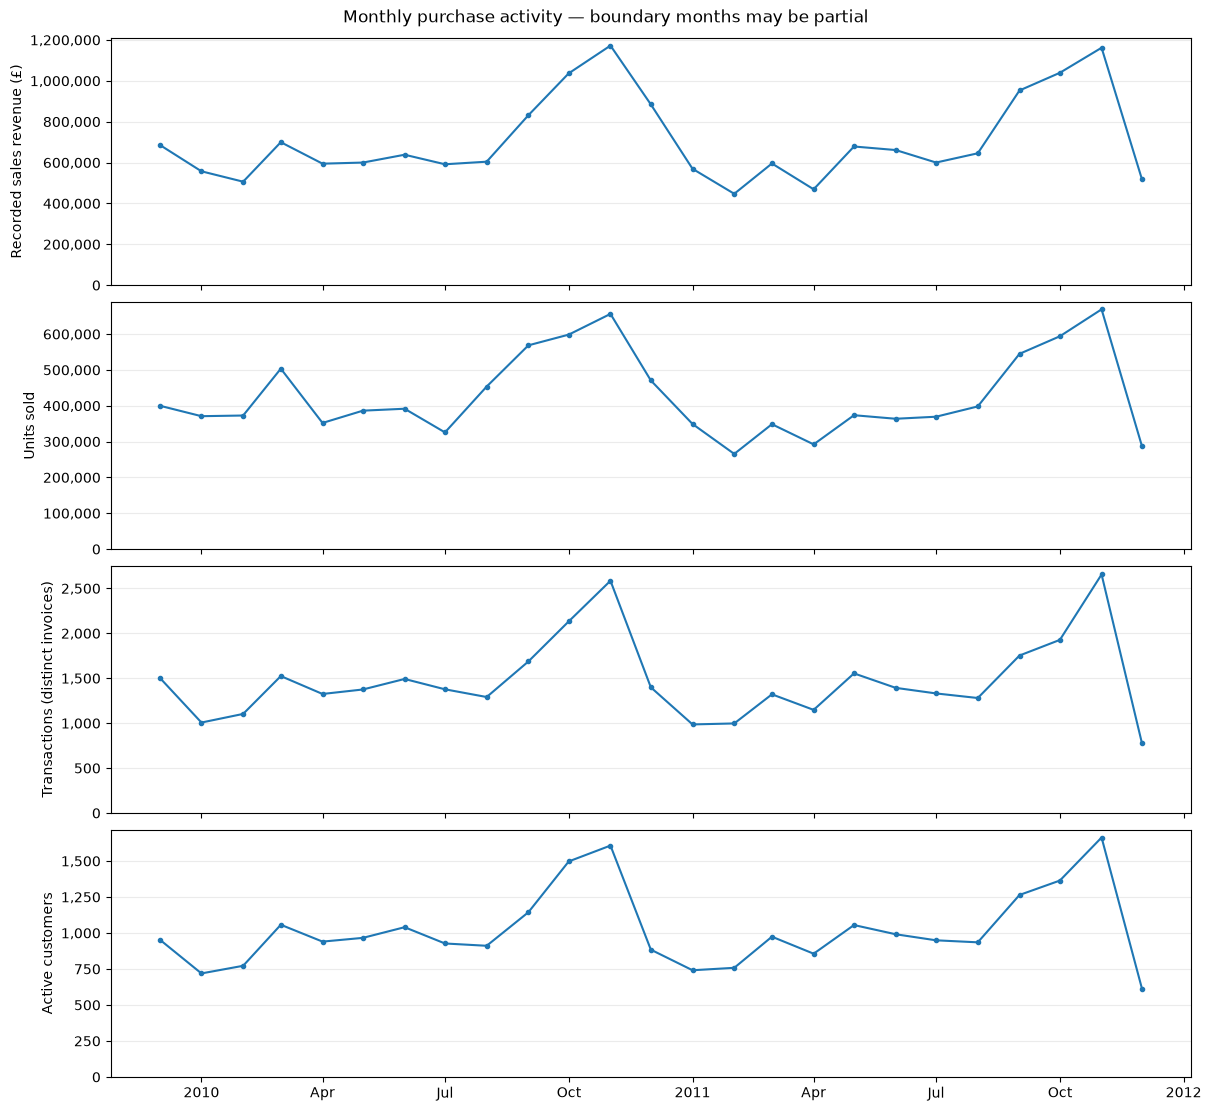

In [ ]:
coverage_start = df["InvoiceDate"].min()
coverage_end = df["InvoiceDate"].max()
print(f"Observed transactions: {coverage_start} to {coverage_end}")
plot_sales_over_time(monthly, "Monthly purchase activity — boundary months may be partial")
plt.show()

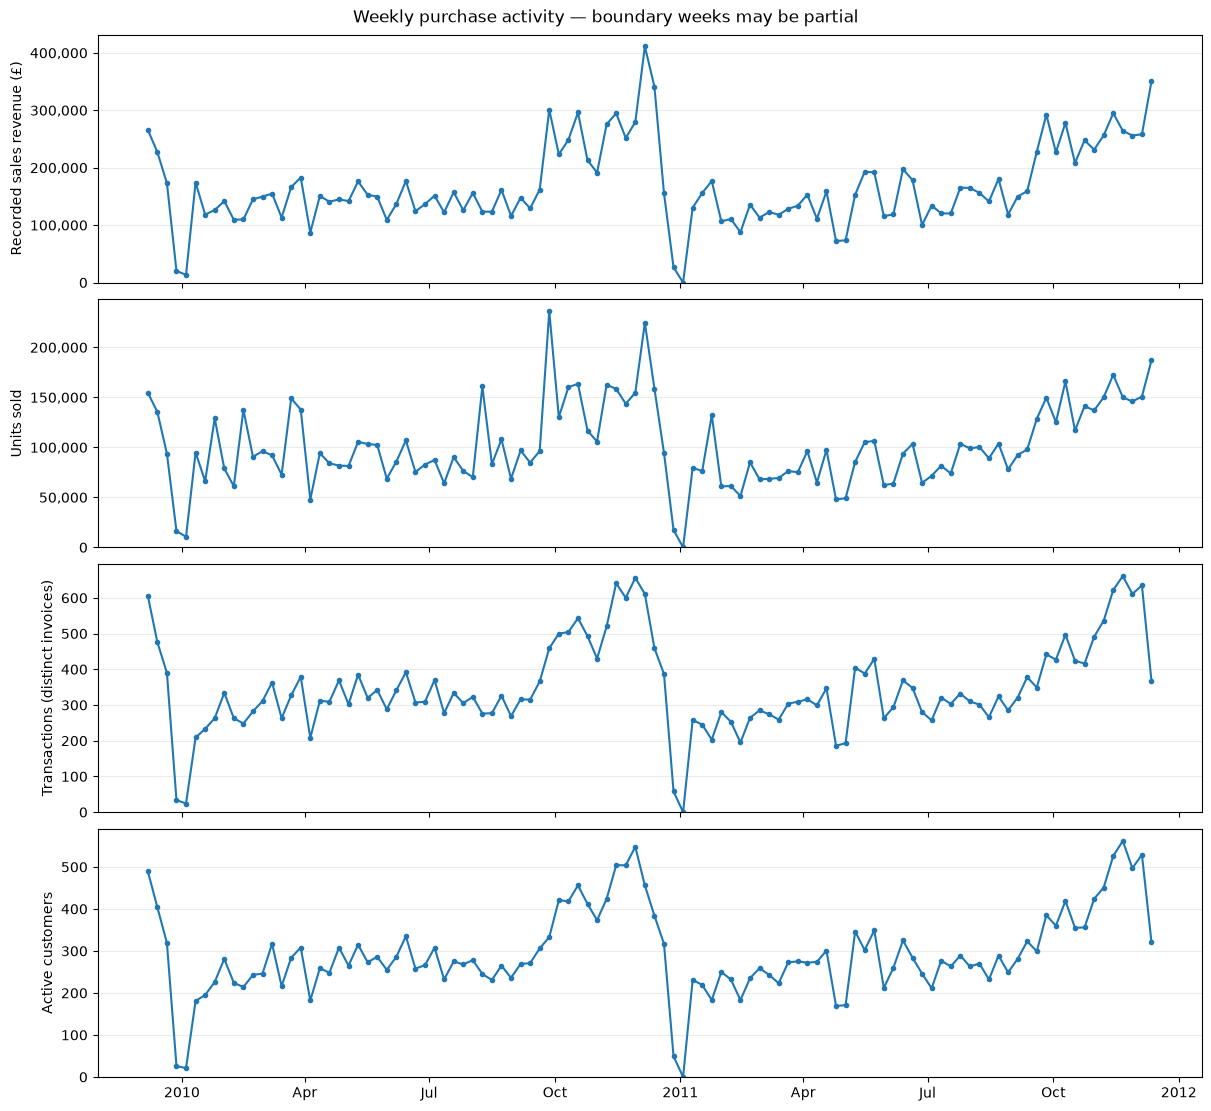

In [17]:
# Weekly buckets end on Monday (pandas W-MON convention).
plot_sales_over_time(weekly, "Weekly purchase activity — boundary weeks may be partial")
plt.show()

## Calendar-month patterns

Compare the same month across years to look for repeatable patterns. These totals are not
adjusted for month length or trading days. Two annual cycles provide limited evidence of
seasonality; growth, customer mix, or unusual events can produce similar patterns.


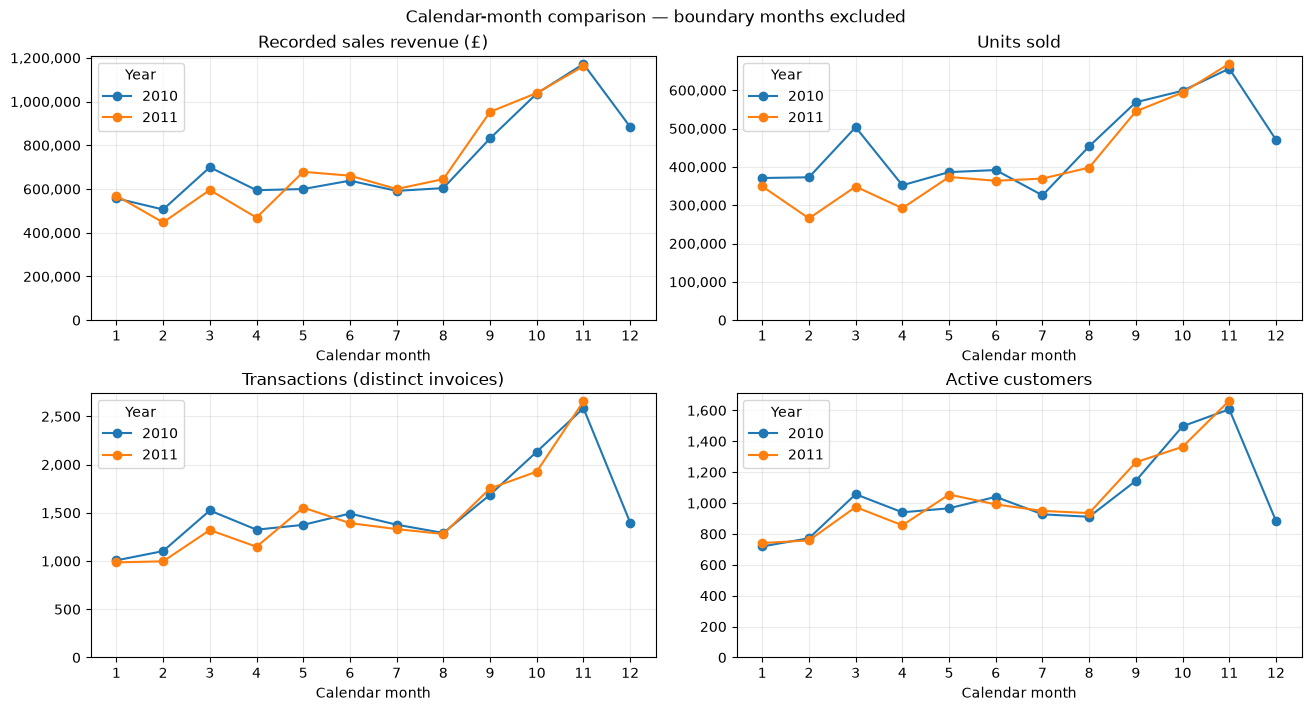

In [18]:
complete_months = monthly.loc[
    (monthly.index.to_period("M") > coverage_start.to_period("M"))
    & (monthly.index.to_period("M") < coverage_end.to_period("M"))
]
plot_monthly_seasonality(complete_months)
plt.show()

Seasonal trends are preserved along the years, we have a small surge on units sold on March but revenue stays unchanged for this period. From January to July trends are stable, then in August every measure starts to increase, where the peak occurs in November and falls again in December. The intuition in `01_eda.ipynb` was right: activity is concentrated in the last third or quarter of the year.

## Transactions by country

Country describes the recorded customer location. Each invoice counts once.
The second panel excludes the UK to make smaller markets visible; its percentages
still use **all** retained invoices as the denominator. `Unspecified` stays separate.


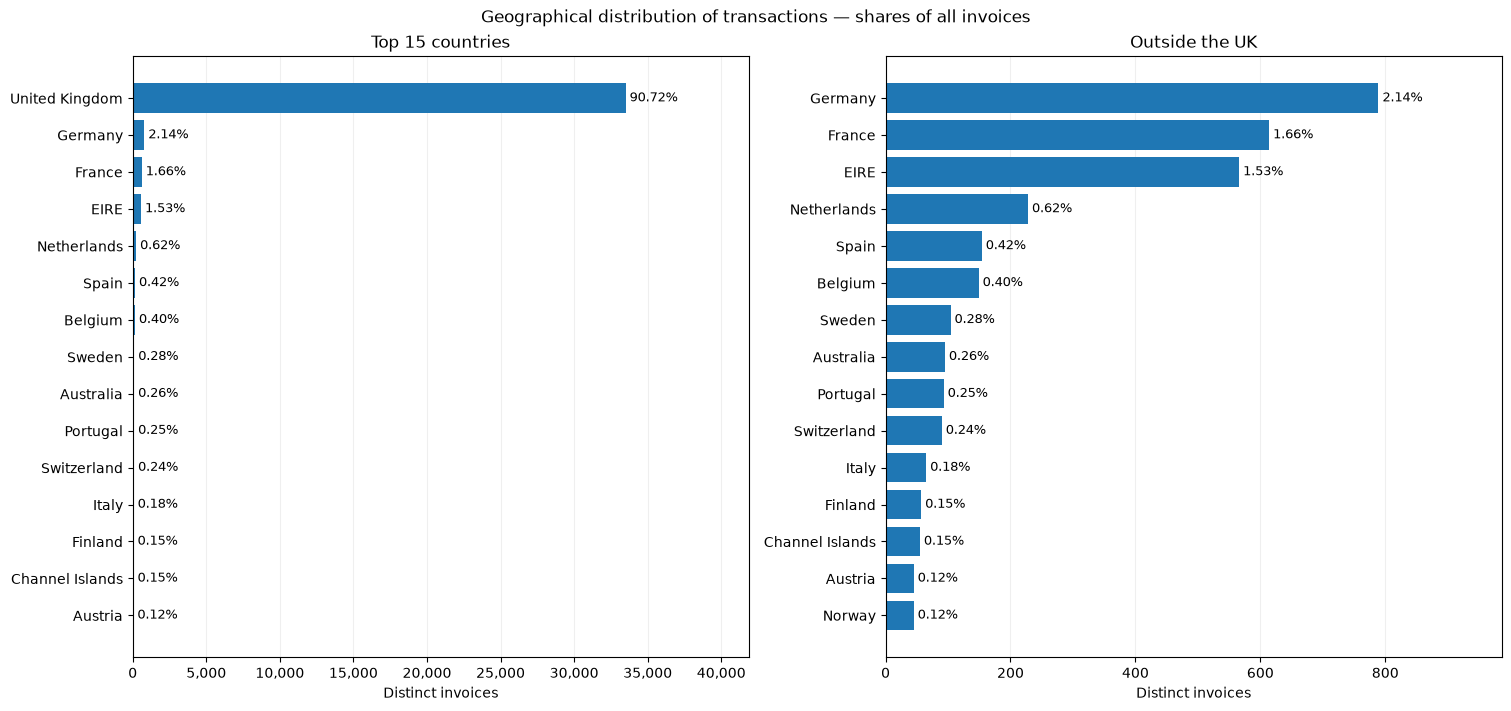

In [19]:
countries = transactions_by_country(df)
plot_country_transactions(countries)
plt.show()

In [21]:
# Full ranking includes countries omitted from the plots.
countries.round({"share_pct": 2}).head(5)

,transactions,share_pct
Country,,
United Kingdom,33499,90.72
Germany,789,2.14
France,614,1.66
EIRE,566,1.53
Netherlands,228,0.62


The UK comprises a 90.72% share of total transactions. We do not have enough information on other countries for this feature to be relevant. We will ignore this feature for the analysis.

## Customer behaviour

These tables describe observed, identified purchases and are exploratory, not modeling
snapshots. We conservatively exclude the final calendar day because its coverage may be
incomplete. First observed purchase is not necessarily the customer’s first-ever purchase.
Do not reuse full-history totals to predict earlier dates.


In [22]:
from online_retail.analysis.customers import (
    customer_history,
    monthly_customer_activity,
    cohort_repeat_rates,
    plot_customer_distributions,
    plot_customer_activity,
)

analysis_cutoff = df["InvoiceDate"].max().normalize()
customers, purchase_days = customer_history(df, analysis_cutoff)
customers.head()


,first_purchase,last_purchase,invoices,purchase_days,monetary,units,recency_days,observed_history_days,gap_mean,gap_std
Customer ID,,,,,,,,,,
12346,2010-03-02 13:08:00,2011-01-18 10:01:00,3,3,77352.96,74239,324.582639,646.452778,161.000000,60.811183
12347,2010-10-31 14:20:00,2011-12-07 15:52:00,8,8,5633.32,3286,1.338889,403.402778,57.428571,19.051309
12348,2010-09-27 14:59:00,2011-09-25 13:13:00,5,5,2019.40,2714,74.449306,437.375694,90.750000,57.407171
12349,2010-04-29 13:20:00,2011-11-21 09:51:00,4,4,4428.69,1624,17.589583,588.444444,190.333333,186.508266
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,1,334.40,197,309.332639,309.332639,NaN,NaN


In [23]:
customers.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T


,count,mean,min,25%,50%,75%,90%,95%,99%,max,std
first_purchase,5877,2010-08-22 05:21:59.795814144,2009-12-01 07:45:00,2010-02-09 14:17:00,2010-06-27 13:29:00,2011-01-30 14:13:00,2011-09-11 15:23:12,2011-10-19 14:06:48,2011-11-24 13:57:02.400000,2011-12-08 13:11:00,NaN
last_purchase,5877,2011-05-22 09:10:00.030627840,2009-12-01 09:55:00,2010-11-25 10:11:00,2011-09-05 09:48:00,2011-11-14 08:56:00,2011-12-01 08:45:36,2011-12-05 17:13:48,2011-12-08 12:52:28.800000,2011-12-08 20:01:00,NaN
invoices,5877.0,6.276161,1.0,1.0,3.0,7.0,13.0,21.0,46.0,397.0,12.970241
purchase_days,5877.0,5.621405,1.0,1.0,3.0,6.0,12.0,18.0,39.0,255.0,9.972073
monetary,5877.0,2987.517415,2.9,348.59,897.62,2303.17,5588.27,9505.624,29038.4424,608352.21,14573.56777
units,5877.0,1806.278373,1.0,190.0,490.0,1371.0,3232.4,5435.4,17017.84,367193.0,8901.982703
recency_days,5877.0,200.618055,0.165972,24.627778,94.591667,378.575694,534.448611,624.486944,725.382556,737.586806,209.342618
observed_history_days,5877.0,473.776391,0.450694,312.407639,529.438194,667.404861,729.423889,734.517222,737.425694,737.677083,223.008484
gap_mean,4187.0,110.930848,1.0,43.923077,79.444444,141.875,238.0,345.9,513.0,714.0,102.056322
gap_std,3180.0,66.266369,0.0,25.982845,49.942415,87.48796,143.557009,185.47507,272.236111,436.284884,58.591803


In [24]:
history_sizes = pd.DataFrame({
    "customers": [
        customers["invoices"].eq(1).sum(),
        customers["invoices"].between(2, 3).sum(),
        customers["invoices"].ge(4).sum(),
    ]
}, index=["1 invoice", "2–3 invoices", "4+ invoices"])
history_sizes["share_pct"] = history_sizes["customers"] / len(customers) * 100
history_sizes.round(2)


,customers,share_pct
1 invoice,1624,27.63
2–3 invoices,1611,27.41
4+ invoices,2642,44.95


### History length, RFM, and purchase gaps

The curves show the fraction of observations at or below each value. Invoice counts,
purchase days and monetary value use logarithmic x-axes to retain the full long tails.
The gap curve weights completed purchase-day gaps, not customers, and excludes
customers who never returned and unfinished waiting times. It is not a return-probability
estimate for the whole customer population. Sparse customers remain in the customer table;
gap mean/std stay missing when insufficient history is available.


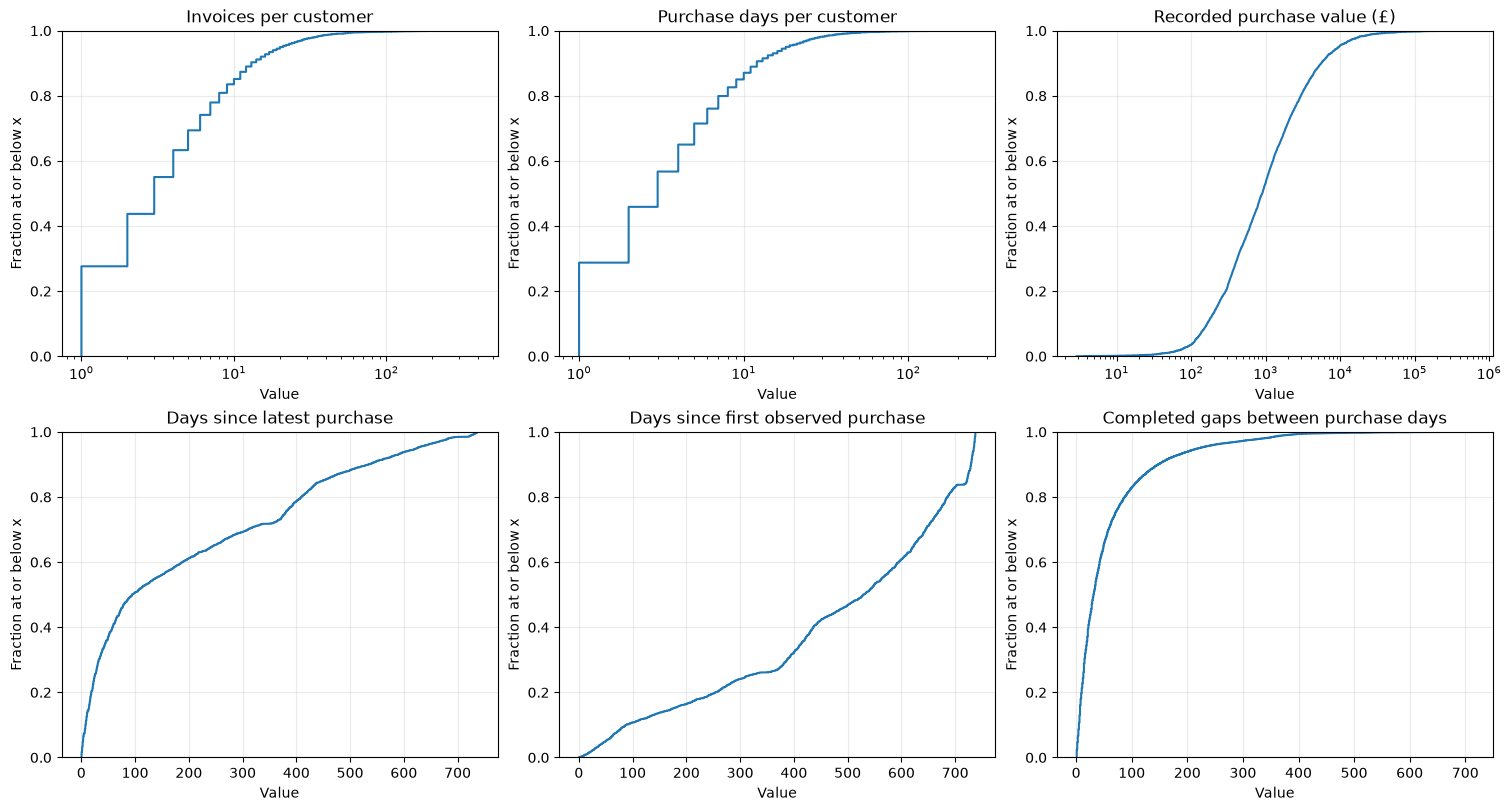

In [26]:
plot_customer_distributions(customers, purchase_days)
plt.show()


### Monthly composition and repeat purchase by cohort

First-observed customers and returning customers partition each month’s active customers.
A customer is counted once per month; first/last months may have partial coverage.
The opening cohort includes customers acquired before the dataset began.

Cohort curves measure a second **distinct purchase day** before 21, 50 or 90 days have
elapsed since the first observed purchase day. Cohorts without full follow-up for every
member are left blank. This is exploratory cohort analysis, not our scoring-date target.


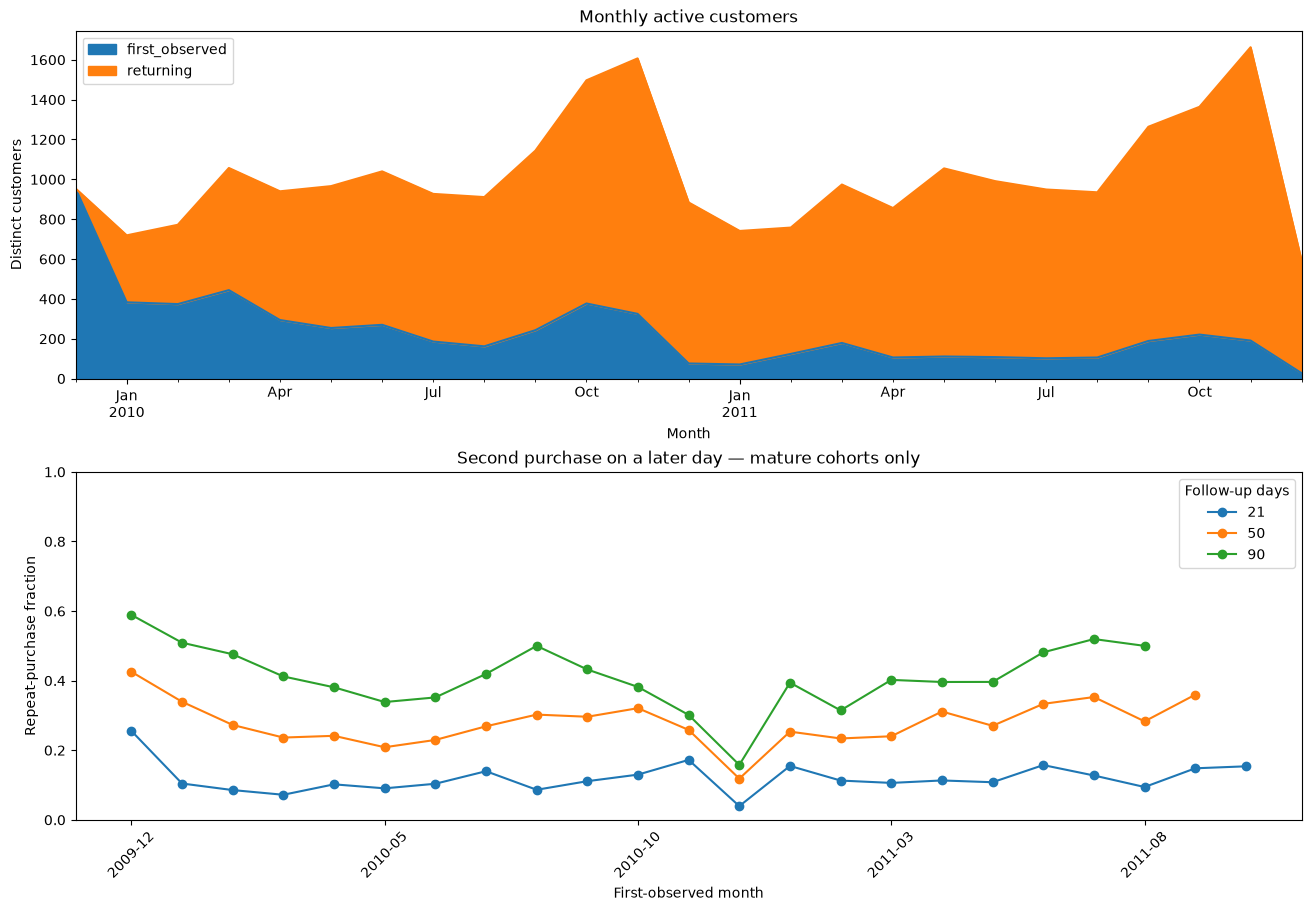

In [27]:
customer_activity = monthly_customer_activity(purchase_days)
repeat_rates = cohort_repeat_rates(customers, purchase_days, analysis_cutoff)
plot_customer_activity(customer_activity, repeat_rates)
plt.show()


In [28]:
repeat_rates.pivot(index="cohort", columns="horizon_days", values="repeat_rate").round(3)


horizon_days,21,50,90
cohort,,,
2009-12,0.256,0.426,0.589
2010-01,0.104,0.339,0.509
2010-02,0.086,0.273,0.476
2010-03,0.072,0.236,0.412
2010-04,0.102,0.241,0.381
2010-05,0.091,0.209,0.339
2010-06,0.104,0.230,0.352
2010-07,0.140,0.269,0.419
2010-08,0.086,0.302,0.500


### Historical recency at selected cutoffs

Each curve includes only customers observed before its cutoff, using only their past
purchases. Changes can reflect cohort mix, coverage, and seasonality—not just inactivity.


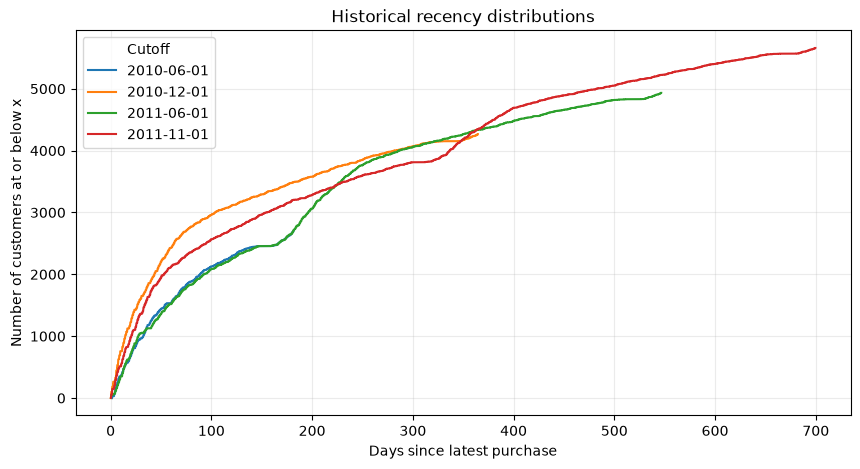

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
for cutoff in ["2010-06-01", "2010-12-01", "2011-06-01", "2011-11-01"]:
    history, _ = customer_history(df, cutoff)
    recency = history["recency_days"].sort_values()
    ax.step(recency, range(1, len(recency) + 1), where="post", label=cutoff)
ax.set(xlabel="Days since latest purchase", ylabel="Number of customers at or below x",
       title="Historical recency distributions")
ax.legend(title="Cutoff")
ax.grid(alpha=0.25)
plt.show()


### Initial observations from the current data

- With the final partial day excluded, 27.63% of customers have one invoice, 27.41% have 2–3, and 44.95% have at least four. Keeping sparse histories matters for population coverage.
- The median customer has three invoices. The median **completed purchase-day gap** is 31 days; this is not the median return time of all customers.
- Returning customers contribute substantially to the late-year active-customer peaks in both years. First-observed counts also change, so total sales alone do not isolate customer retention.
- December 2011 is incomplete. Its activity drop should not be interpreted as a seasonal collapse.
- Cohort return rates vary with first-observed month, but the opening cohort is left-truncated and only two annual cycles are observed. Treat apparent seasonality as a hypothesis.


## Feature Engineering

Designing seasonal and RFM (Recency, Frequency, Monetary) features for customers.

### Weekly point-in-time features and outcomes

Every Monday, include all identified customers with an earlier purchase. Features use
all prior history plus 30/90-day activity. Outcomes require 50 complete future days.
Class 0 = days 0–20; class 1 = days 21–49; class 2 = no purchase in those intervals.
The final source calendar day is excluded conservatively. Missing gaps are retained.

Training labels finish before December 1, 2010; validation cutoffs cover December–March.
Refit uses all mature snapshots on June 1, 2011; test begins afterward. Separate RFM
segmenters are fitted on train and refit only. No classifier is trained. See
[decisions](../docs/problem-definition.md) and [features](../docs/features.md).


In [5]:
import tomllib

from online_retail.features.build import build_feature_datasets

with (ROOT / "configs/prediction.toml").open("rb") as handle:
    feature_settings = tomllib.load(handle)

feature_manifest = build_feature_datasets(
    source=ROOT / "data/interim/purchases.parquet",
    output=ROOT / "data/processed",
    settings=feature_settings,
)


In [6]:
# Inspect construction metadata only; feature statistical analysis comes next.
pd.DataFrame(feature_manifest["partitions"]).T


,rows,customers,first_cutoff,last_cutoff
train,92319,3687,2010-03-01 00:00:00,2010-10-11 00:00:00
validation,75608,4693,2010-12-06 00:00:00,2011-03-28 00:00:00
refit,205510,4753,2010-03-01 00:00:00,2011-04-11 00:00:00
test,104034,5558,2011-06-06 00:00:00,2011-10-17 00:00:00


In [7]:
# Ready for the next statistical-analysis step; no analysis is performed here.
feature_tables = {
    name: pd.read_parquet(ROOT / "data/processed" / f"{name}.parquet")
    for name in ("train", "validation", "refit", "test")
}
feature_columns = feature_manifest["feature_columns"]


### Saved datasets

`data/processed/` contains `train.parquet`, `validation.parquet`, `refit.parquet`,
and `test.parquet`, plus the two fitted RFM segmenters and `manifest.json`.
Refit overlaps earlier partitions intentionally. Use the manifest’s `feature_columns`
for predictors; exclude Customer ID, cutoff, and NextPurchaseRange.

The RFM score combines engagement and spending: scores 3–4 are low, 5–7 medium,
and 8–9 high. Keep the continuous features too. Internal model-selection folds
must refit RFM clustering and other learned preprocessing within each fold.

Feature statistical analysis and classifier modeling are intentionally deferred.
